In [3]:
import time
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

In [4]:
def conv(x, h):
    N = len(x) + len(h) - 1
    y = np.zeros(N)
    for n in range(N):
        for k in range(len(x)):
            if 0 <= n - k < len(h):
                y[n] += x[k] * h[n - k]
    return y

In [5]:
print(conv([1, 2, 3, 1], [1, 1, 1, 1]))
print(np.convolve([1, 2, 3, 1], [1, 1, 1, 1]))

[1. 3. 6. 7. 6. 4. 1.]
[1 3 6 7 6 4 1]


In [6]:
print(conv([1, -1, 2], [2, 1, 0, 1]))
print(np.convolve([1, -1, 2], [2, 1, 0, 1]))

[ 2. -1.  3.  3. -1.  2.]
[ 2 -1  3  3 -1  2]


In [7]:
rng = np.random.default_rng(0)
a = rng.standard_normal(2000)
b = rng.standard_normal(2000)

t0 = time.perf_counter(); y1 = conv(a, b);        t_conv = time.perf_counter() - t0
t0 = time.perf_counter(); y2 = np.convolve(a, b); t_np   = time.perf_counter() - t0

print(f"conv: {t_conv:.3f} s | np.convolve: {t_np*1e3:.2f} ms | ratio: {t_conv/t_np:.0f}x")
print("same result:", np.allclose(y1, y2))

conv: 3.041 s | np.convolve: 1.43 ms | ratio: 2124x
same result: True


In [8]:
rng = np.random.default_rng(1)
n = np.arange(300)
x = np.sin(2*np.pi*n/50) + 0.5*rng.standard_normal(300)

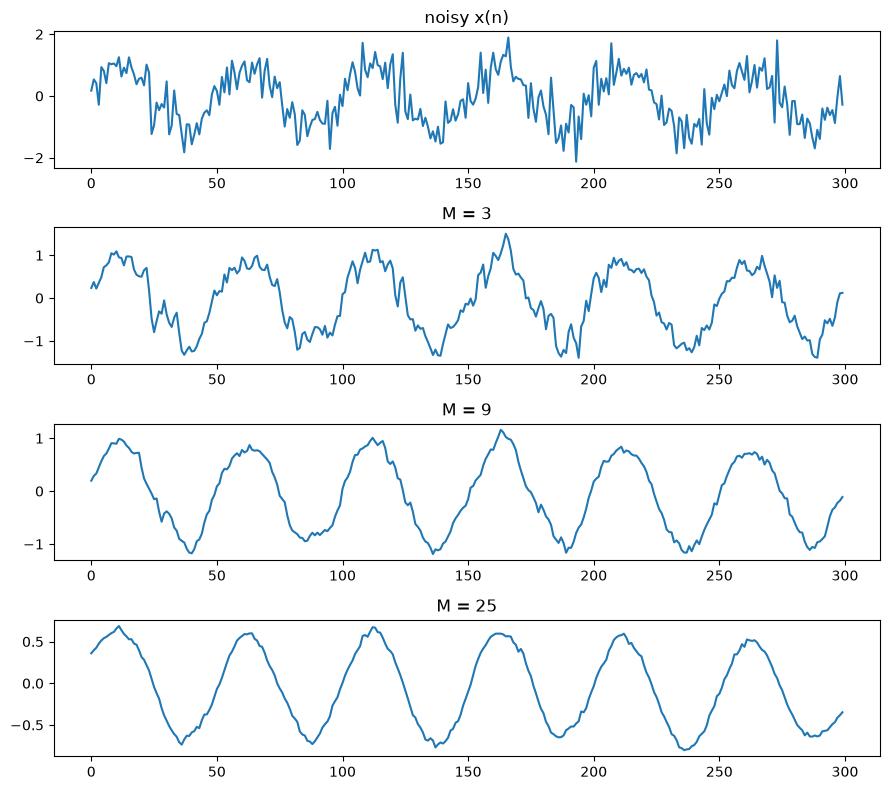

In [9]:
plt.figure(figsize=(9, 8))
plt.subplot(4, 1, 1); plt.plot(n, x); plt.title("noisy x(n)")
for i, M in enumerate([3, 9, 25], start=2):
    h = np.ones(M)/M                          # moving-average filter
    y = np.convolve(x, h, mode="same")
    plt.subplot(4, 1, i); plt.plot(n, y); plt.title(f"M = {M}")
plt.tight_layout(); plt.show()

In [10]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
%matplotlib inline

In [11]:
rng = np.random.default_rng(0)
x1, x2 = rng.standard_normal(50), rng.standard_normal(50)
a, b = 2.0, -3.0
systems = {"x^2": lambda x: x**2,
           "n x(n)": lambda x: np.arange(len(x)) * x,
           "moving average": lambda x: np.convolve(x, np.ones(3)/3)[:len(x)]}
for name, T in systems.items():
    linear = np.allclose(T(a*x1 + b*x2), a*T(x1) + b*T(x2))
    xd = np.concatenate([np.zeros(5), x1])[:50]        # delay input by 5
    yd = np.concatenate([np.zeros(5), T(x1)])[:50]     # delay output by 5
    tinv = np.allclose(T(xd), yd)
    print(f"{name:15s} linear={linear} time-invariant={tinv}")

x^2             linear=False time-invariant=True
n x(n)          linear=True time-invariant=False
moving average  linear=True time-invariant=True


Linear: T{a·x₁ + b·x₂} = a·T{x₁} + b·T{x₂}.
Time-invariant: delaying the input by n₀ delays the output by n₀.
x²: not linear, because (a·x₁ + b·x₂)² has a cross term 2ab·x₁x₂. It is time-invariant, because squaring does not depend on n.
n·x(n): linear, but not time-invariant, because the gain n changes with time. The delayed input gives n·x(n − 5), while the delayed output is (n − 5)·x(n − 5).
Moving average: linear and time-invariant, so it is an LTI system.

estimated delay: 37 samples


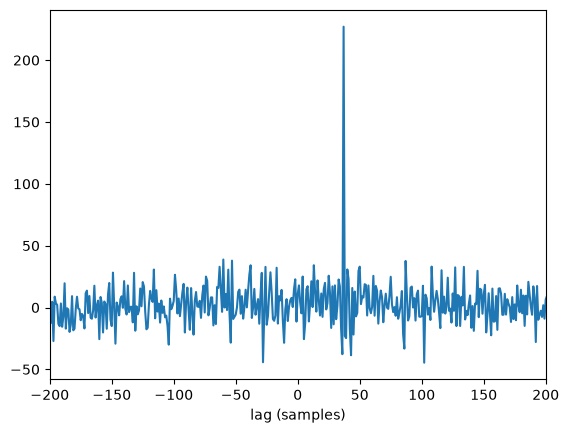

In [12]:
rng = np.random.default_rng(1)
fs = 1000
x = rng.standard_normal(500)                    # transmitted signal
true_delay = 37
y = np.concatenate([np.zeros(true_delay), 0.6*x])[:500] + 0.5*rng.standard_normal(500)
r = signal.correlate(y, x, mode="full")
lags = signal.correlation_lags(len(y), len(x), mode="full")
print("estimated delay:", lags[np.argmax(r)], "samples")
plt.plot(lags, r); plt.xlim(-200, 200); plt.xlabel("lag (samples)"); plt.show()

In [13]:
for noise in [0.5, 1, 2, 4]:
    rng = np.random.default_rng(1)
    x = rng.standard_normal(500)
    y = np.concatenate([np.zeros(true_delay), 0.6*x])[:500] + noise*rng.standard_normal(500)
    r = signal.correlate(y, x, mode="full")
    print(f"noise std = {noise}: estimated delay = {lags[np.argmax(r)]} samples")

noise std = 0.5: estimated delay = 37 samples
noise std = 1: estimated delay = 37 samples
noise std = 2: estimated delay = 37 samples
noise std = 4: estimated delay = 87 samples


In [14]:
delay_s = true_delay / fs
print(delay_s, "s ->", 343 * delay_s, "m")

0.037 s -> 12.690999999999999 m


In [15]:
N = 10
x_imp = np.zeros(N); x_imp[0] = 1
h_rec = np.zeros(N)
for n in range(N):
    h_rec[n] = (x_imp[n] + (x_imp[n-1] if n >= 1 else 0)
                + 0.75*(h_rec[n-1] if n >= 1 else 0)
                - 0.125*(h_rec[n-2] if n >= 2 else 0))
print(h_rec)

[1.         1.75       1.1875     0.671875   0.35546875 0.18261719
 0.0925293  0.04656982 0.02336121 0.01169968]


In [16]:
h_lf = signal.lfilter([1, 1], [1, -0.75, 0.125], x_imp)
print(h_lf)

[1.         1.75       1.1875     0.671875   0.35546875 0.18261719
 0.0925293  0.04656982 0.02336121 0.01169968]


In [17]:
n = np.arange(N)
h_cf = 6*0.5**n - 5*0.25**n
print(h_cf)
print(np.allclose(h_rec, h_lf), np.allclose(h_lf, h_cf))   # True True

[1.         1.75       1.1875     0.671875   0.35546875 0.18261719
 0.0925293  0.04656982 0.02336121 0.01169968]
True True


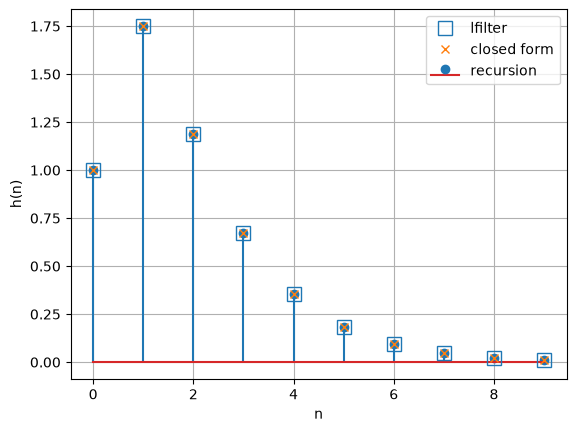

In [18]:
plt.stem(n, h_rec, label="recursion")
plt.plot(n, h_lf, "s", mfc="none", ms=10, label="lfilter")
plt.plot(n, h_cf, "x", label="closed form")
plt.xlabel("n"); plt.ylabel("h(n)"); plt.legend(); plt.grid(True); plt.show()

In [19]:
step = signal.lfilter([1, 1], [1, -0.75, 0.125], np.ones(60))
print("final value of step response:", step[-1])
print("H(1) = sum(b)/sum(a):", sum([1, 1]) / sum([1, -0.75, 0.125]))

final value of step response: 5.333333333333333
H(1) = sum(b)/sum(a): 5.333333333333333


1. Why is np.convolve so much faster than your double loop? What is the number of multiplications for lengths 𝐿 and 𝑀?
My conv runs in the Python interpreter, which looks up x[k] and h[n-k], tests the if, and updates y[n] for each of the L·M steps. np.convolve does the same L·M multiplications in compiled C code on contiguous arrays, without the interpreter overhead. In my timing, conv took ___ s and np.convolve took ___ ms, a ratio of ___. The number of multiplications is L × M, giving a result of L + M − 1 samples. For long signals, FFT-based convolution (signal.fftconvolve) is faster still.

2. Which of the three systems in Task 3.3 are LTI? Could you have predicted this without running code?
x^2             linear=False time-invariant=True
n x(n)          linear=True time-invariant=False
moving average  linear=True time-invariant=True

3. Give two engineering applications of cross-correlation in Tanzania (e.g. locating leaks in water pipes, GPS, radar at airports).
Only the moving average is LTI. x² is not linear because of the cross term 2ab·x₁x₂. n·x(n) is linear but not time-invariant because its gain n depends on time. The moving average is a fixed weighted sum, so it is both linear and time-invariant and can be written as convolution with h = {⅓, ⅓, ⅓}. Yes, this can be predicted from the equations without running code.

4. Is the system in Task 3.5 FIR or IIR? Stable? Justify from the impulse response.
The system is IIR: the impulse response h(n) = 6(0.5)ⁿ − 5(0.25)ⁿ decays forever and is never exactly zero (h(9) ≈ 0.0117), which comes from the feedback terms in the difference equation. It is stable: h(n) decays geometrically, so Σ|h(n)| is finite (≈ 5.333, equal to H(1)). Equivalently, the poles are at 0.5 and 0.25, both inside the unit circle, so a bounded input gives a bounded output.

 AI-use statement

I used an AI assistant (Claude) while working on this lab. It helped me set up Python and Jupyter, explained the theory behind convolution, linearity and time-invariance, cross-correlation and difference equations, and showed me example code and worked answers to the pre-lab and analysis questions. I ran all the code myself in my own notebook, checked that the outputs matched (for example, my `conv` function against `np.convolve`), and wrote my own observations and conclusions, using the AI's explanations as a guide.